In [2]:
import matplotlib.pyplot as plt
import sys
import socket
from lab_hydraharp import HydraHarp

# ---------------------------------------------------------------------
# Local component imports
# ---------------------------------------------------------------------

if socket.gethostname() == "ph-photonbec5":
    sys.path.append(r"D:/Control/PythonPackages/")

import Components as comp


# ---------------------------------------------------------------------
# Hardware setup
# ---------------------------------------------------------------------

laser = comp.Toptica_Laser()


powermeter = comp.Thor_PowerMeter(
    power_meter_usb_name='USB0::0x1313::0x8078::P0046773::INSTR',
    num_power_readings=15,
    bs_factor=1,
    wavelength=950
)

hh = HydraHarp()
def measure_histogram(hh, seconds=10, channel=0):
    """Clear old counts and return a fresh histogram plus acquisition metadata."""
    if not 0 <= channel < hh.channels:
        raise ValueError("Invalid input channel")
    hh.start(seconds)  # Clears histogram memory; this wrapper allows 0 < seconds <= 60.
    try:
        deadline = time.monotonic() + seconds + 10
        while not hh.complete():
            if time.monotonic() > deadline:
                raise TimeoutError("HydraHarp did not finish")
            time.sleep(0.05)
    finally:
        result = hh.stop_read()  # Also stops acquisition if interrupted.
    counts = np.asarray(result["histograms"][channel], dtype=np.uint32)
    delay_ns = np.arange(counts.size) * hh.settings["resolution_ps"] / 1000
    return delay_ns, counts, result
# ---------------------------------------------------------------------
# Utility functions
# ---------------------------------------------------------------------

def make_data_folder(base_directory='D:/Data'):
    year = datetime.now().strftime('%Y')
    year_month = datetime.now().strftime('%Y%m')
    year_month_day = datetime.now().strftime('%Y%m%d')

    folder_path = os.path.join(
        base_directory,
        year,
        year_month,
        year_month_day
    )

    os.makedirs(folder_path, exist_ok=True)
    return folder_path


def format_for_filename(x):
    """Keep decimal points in filenames but remove spaces."""
    return str(x).strip().replace(" ", "")


def save_arrays(
        voltage_array,
        time_array,
        commanded_power_mW,
        measured_power_uW,
        iteration,
        gain_value,
        base_directory='D:/Data',
        save_time_once=True
):
    folder_path = make_data_folder(base_directory)
    timestamp = datetime.now().strftime('%H%M%S')

    laserp_str = f"{commanded_power_mW:.3g}"
    measp_str = f"{measured_power_uW:.3g}"
    gain_str = format_for_filename(gain_value)

    suffix = (
        f"laserp_{laserp_str}_mW"
        f"_measp_{measp_str}_uW"
        f"_iter{iteration:03d}"
        f"_gain_{gain_str}"
    )

    voltage_filename = f"pbec_{timestamp}_{suffix}_Voltage.txt"
    voltage_path = os.path.join(folder_path, voltage_filename)

    np.savetxt(voltage_path, voltage_array, fmt='%0.4f')

    time_path = None

    if save_time_once:
        time_filename = "pbec_Time.txt"
        time_path = os.path.join(folder_path, time_filename)

        if not os.path.exists(time_path):
            np.savetxt(time_path, time_array, fmt='%0.4f')

    return voltage_path, time_path

ThorlabsBackendError: backend exception: VisaIOError('VI_ERROR_RSRC_NFOUND (-1073807343): Insufficient location information or the requested device or resource is not present in the system.') ('VI_ERROR_RSRC_NFOUND (-1073807343): Insufficient location information or the requested device or resource is not present in the system.')

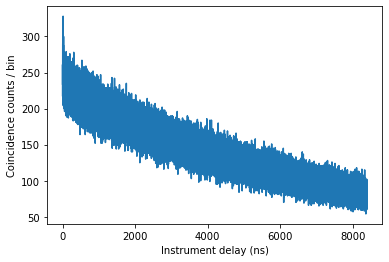

In [3]:
delay_ns, counts, result = measure_histogram(hh)

plt.clf()
plt.plot(delay_ns, counts)
plt.xlabel("Instrument delay (ns)")
plt.ylabel("Coincidence counts / bin")
plt.show()

Measuring 16.00 mW


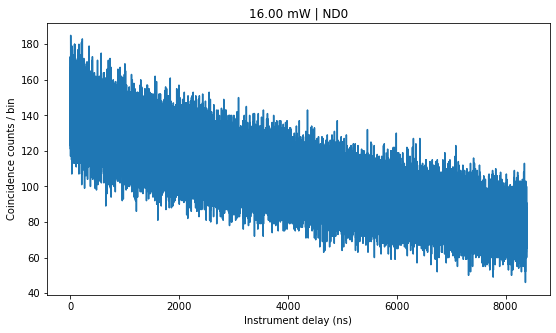

Finished 16.00 mW
Measuring 16.20 mW


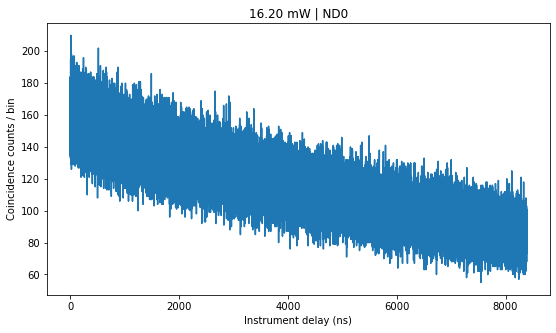

Finished 16.20 mW
Measuring 16.40 mW


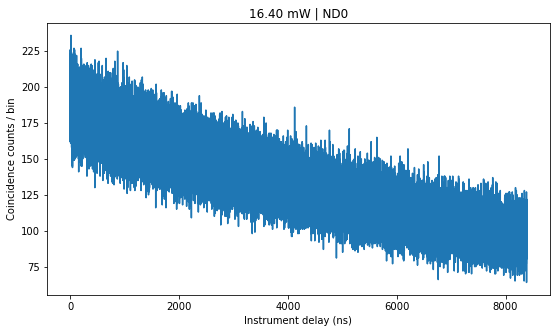

Finished 16.40 mW
Measuring 16.60 mW


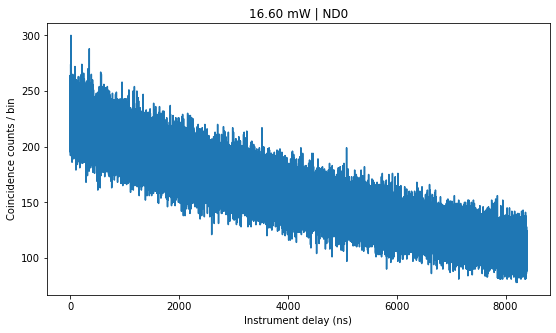

Finished 16.60 mW
Measuring 16.80 mW


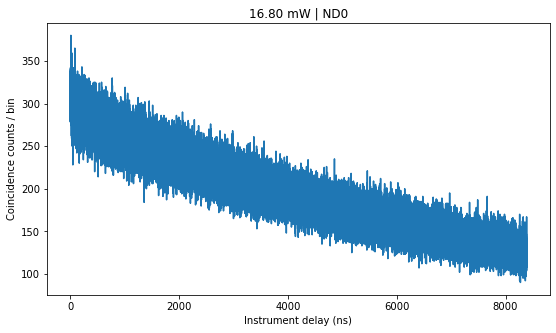

Finished 16.80 mW
Measuring 17.00 mW


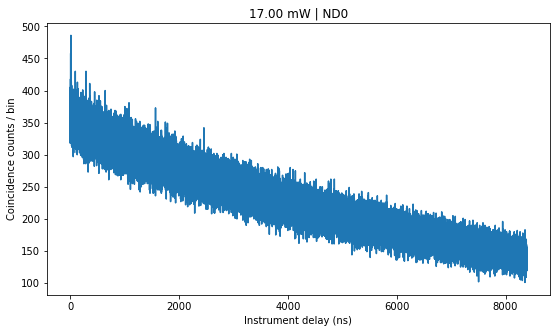

Finished 17.00 mW
Measuring 17.20 mW


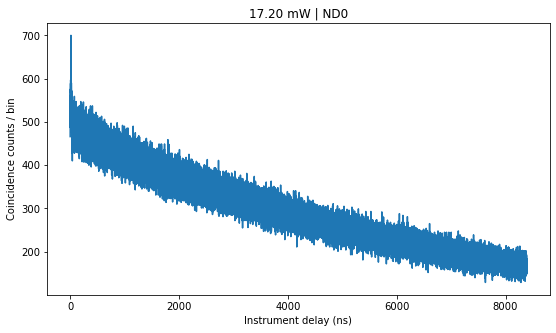

Finished 17.20 mW
Measuring 17.40 mW


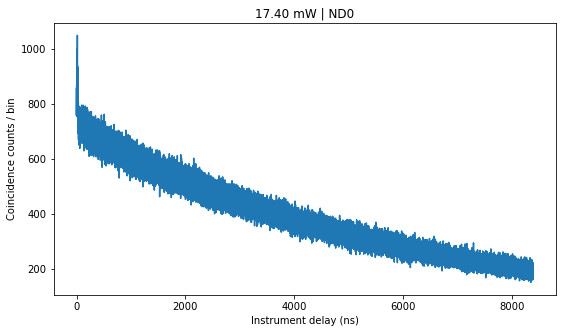

Finished 17.40 mW
Measuring 17.60 mW


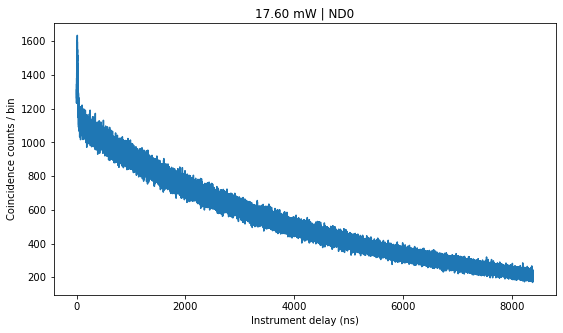

Finished 17.60 mW
ND0 SCAN COMPLETE — stop here and change filter.


In [5]:

import numpy as np
import matplotlib.pyplot as plt
import os
import time
from datetime import datetime
from IPython.display import display

P_min = 16.0
P_max = 17.6
P_step = 0.2
ND = "ND0"

folder = os.path.join(
    make_data_folder(),
    "Lab3_ND0_" + datetime.now().strftime("%H%M%S")
)
os.makedirs(folder, exist_ok=True)

powers = np.round(np.arange(P_min, P_max + P_step/2, P_step), 3)

for power in powers:
    print(f"Measuring {power:.2f} mW", flush=True)

    laser.set(float(power) / 1000)
    time.sleep(2)

    delay_ns, counts, result = measure_histogram(
        hh, seconds=20, channel=0
    )

    name = f"{power:.2f}mW_{ND}"

    np.savez(
        os.path.join(folder, name + ".npz"),
        delay_ns=delay_ns,
        counts=counts,
        power_mW=power,
        ND=ND
    )

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(delay_ns, counts)
    ax.set_xlabel("Instrument delay (ns)")
    ax.set_ylabel("Coincidence counts / bin")
    ax.set_title(f"{power:.2f} mW | {ND}")

    fig.savefig(os.path.join(folder, name + ".png"), dpi=150)
    display(fig)
    plt.close(fig)

    print(f"Finished {power:.2f} mW", flush=True)

print("ND0 SCAN COMPLETE — stop here and change filter.")


NameError: name 'make_data_folder' is not defined

NameError: name 'HydraHarp' is not defined

[]
